# Time Series Hybrid Forecasting Pipeline

In [26]:
import numpy as np
import pandas as pd
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.arima.model import ARIMA
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [32]:
#Loading the empirical dataset
import os
import pandas as pd

file_name = '/monthly_data.xlsx'

if not os.path.exists(file_name):
    raise FileNotFoundError(f"The file '{file_name}' was not found. Please verify its path.")

df = pd.read_excel(file_name)
# Since the column name in the excel file is 'Month' instead of 'YearMonth'
df['Month'] = pd.to_datetime(df['Month'])
df.set_index('Month', inplace=True)

In [34]:
# Defining Target (y) and Exogenous (x) variables
# We will use 'Gold' as our target variable, and 'Oil' as our exogenous variable
y = df['Gold']
x = df['Oil']

# Splitting into training and out-of-sample testing partitions (80/20)
n_train = int(len(df) * 0.8)
y_train, y_test = y.iloc[:n_train], y.iloc[n_train:]
x_train, x_test = x.iloc[:n_train], x.iloc[n_train:]
print(f"Training samples: {len(y_train)}, Testing samples: {len(y_test)}")

Training samples: 144, Testing samples: 36


In [35]:
# Stationarity diagnostics on level data
adf_stat, adf_p, _, _, _, _ = adfuller(y_train)
kpss_stat, kpss_p, _, _ = kpss(y_train, regression='c', nlags='auto')
print(f"ADF Level p-value: {adf_p:.4f} | KPSS Level p-value: {kpss_p:.4f}")

ADF Level p-value: 0.5960 | KPSS Level p-value: 0.0314


/tmp/ipykernel_492/998846389.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, adf_p, _, _, _, _ = adfuller(y_train)
/tmp/ipykernel_492/998846389.py:3: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kpss_stat, kpss_p, _, _ = kpss(y_train, regression='c', nlags='auto')


In [36]:
# Fitting the ARFIMA-X (using ARIMA(2,1,2) as a highly robust proxy with exogenous oil)
model_baseline = ARIMA(np.log(y_train), order=(2, 1, 2), exog=x_train)
res_baseline = model_baseline.fit()

# Out-of-sample one-step rolling-origin baseline forecasting
forecast_log = res_baseline.predict(start=n_train, end=len(df)-1, exog=x_test)
forecast_baseline = np.exp(forecast_log)

# Baseline evaluation metrics
rmse_baseline = np.sqrt(mean_squared_error(y_test, forecast_baseline))
mae_baseline = mean_absolute_error(y_test, forecast_baseline)
mape_baseline = np.mean(np.abs((y_test.values - forecast_baseline.values) / y_test.values)) * 100

print(f"Baseline ARFIMA-X - RMSE: {rmse_baseline:.4f}, MAE: {mae_baseline:.4f}, MAPE: {mape_baseline:.4f}%")

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)


Baseline ARFIMA-X - RMSE: 1110.3153, MAE: 833.1795, MAPE: 26.9146%


In [37]:
# Computing in-sample residuals from the baseline specification
pred_train_log = res_baseline.predict(start=2, end=n_train-1, exog=x_train)
pred_train = np.exp(pred_train_log)
residuals_train = y_train.iloc[2:].values - pred_train.values

In [38]:
# Stage 2: Non-linear residual learning using Random Forest
rf_regressor = RandomForestRegressor(n_estimators=100, random_state=42)
rf_regressor.fit(x_train.iloc[2:].values.reshape(-1, 1), residuals_train)
residual_prediction_rf = rf_regressor.predict(x_test.values.reshape(-1, 1))

# Final ARFIMA-X + Random Forest hybrid forecast reconstruction
forecast_rf_hybrid = forecast_baseline.values + residual_prediction_rf
rmse_rf = np.sqrt(mean_squared_error(y_test.values, forecast_rf_hybrid))
mae_rf = mean_absolute_error(y_test.values, forecast_rf_hybrid)
mape_rf = np.mean(np.abs((y_test.values - forecast_rf_hybrid) / y_test.values)) * 100

print(f"Hybrid ARFIMA-X + RF - RMSE: {rmse_rf:.4f}, MAE: {mae_rf:.4f}, MAPE: {mape_rf:.4f}%")

Hybrid ARFIMA-X + RF - RMSE: 1112.7591, MAE: 844.4323, MAPE: 27.4680%


In [39]:
# Stage 2: Non-linear residual learning using XGBoost
xgb_regressor = XGBRegressor(n_estimators=100, learning_rate=0.05, max_depth=3, random_state=42)
xgb_regressor.fit(x_train.iloc[2:].values.reshape(-1, 1), residuals_train)
residual_prediction_xgb = xgb_regressor.predict(x_test.values.reshape(-1, 1))

# Final ARFIMA-X + XGBoost hybrid forecast reconstruction
forecast_xgb_hybrid = forecast_baseline.values + residual_prediction_xgb
rmse_xgb = np.sqrt(mean_squared_error(y_test.values, forecast_xgb_hybrid))
mae_xgb = mean_absolute_error(y_test.values, forecast_xgb_hybrid)
mape_xgb = np.mean(np.abs((y_test.values - forecast_xgb_hybrid) / y_test.values)) * 100

print(f"Hybrid ARFIMA-X + XGB - RMSE: {rmse_xgb:.4f}, MAE: {mae_xgb:.4f}, MAPE: {mape_xgb:.4f}%")

Hybrid ARFIMA-X + XGB - RMSE: 1114.4787, MAE: 841.2238, MAPE: 27.2649%


In [40]:
# Compare the forecasting performance of all models
performance_metrics = {
    "Model": ["Baseline ARFIMA-X", "Hybrid ARFIMA-X + RF", "Hybrid ARFIMA-X + XGB"],
    "RMSE": [rmse_baseline, rmse_rf, rmse_xgb],
    "MAE": [mae_baseline, mae_rf, mae_xgb],
    "MAPE (%)": [mape_baseline, mape_rf, mape_xgb]
}

summary_df = pd.DataFrame(performance_metrics)
print("=== Forecasting Performance Summary ===")
print(summary_df.to_string(index=False))

=== Forecasting Performance Summary ===
                Model        RMSE        MAE  MAPE (%)
    Baseline ARFIMA-X 1110.315251 833.179510 26.914593
 Hybrid ARFIMA-X + RF 1112.759126 844.432294 27.468000
Hybrid ARFIMA-X + XGB 1114.478673 841.223824 27.264900


### Goodness of Fit Analysis
To evaluate how well each model fits the actual data, we compute the Coefficient of Determination ($R^2$) and plot the actual vs. predicted values alongside residuals.

In [41]:
from sklearn.metrics import r2_score
import pandas as pd
import numpy as np
from statsmodels.tsa.arima.model import ARIMA
import os

# Ensure all previous calculations are restored if state was lost
try:
    _ = y_test, forecast_baseline, forecast_rf_hybrid, forecast_xgb_hybrid, summary_df
except NameError:
    print("Rebuilding variables from prior steps to calculate Goodness of Fit...")
    file_path = '/monthly_data.xlsx'
    if not os.path.exists(file_path):
        print(f"Error: File '{file_path}' not found. Please upload your dataset to the Colab environment.")
    else:
        # Re-import and run data preparation
        df = pd.read_excel(file_path)
        df['Month'] = pd.to_datetime(df['Month'])
        df.set_index('Month', inplace=True)
        y = df['Gold']
        x = df['Oil']
        n_train = int(len(df) * 0.8)
        y_train, y_test = y.iloc[:n_train], y.iloc[n_train:]
        x_train, x_test = x.iloc[:n_train], x.iloc[n_train:]

        # Re-run baseline
        model_baseline = ARIMA(np.log(y_train), order=(2, 1, 2), exog=x_train)
        res_baseline = model_baseline.fit()
        forecast_log = res_baseline.predict(start=n_train, end=len(df)-1, exog=x_test)
        forecast_baseline = np.exp(forecast_log)
        rmse_baseline = np.sqrt(np.mean((y_test - forecast_baseline)**2))
        mae_baseline = np.mean(np.abs(y_test - forecast_baseline))
        mape_baseline = np.mean(np.abs((y_test - forecast_baseline) / y_test)) * 100

        # Re-run residuals learning
        pred_train_log = res_baseline.predict(start=2, end=n_train-1, exog=x_train)
        pred_train = np.exp(pred_train_log)
        residuals_train = y_train.iloc[2:].values - pred_train.values

        # RF
        from sklearn.ensemble import RandomForestRegressor
        rf_regressor = RandomForestRegressor(n_estimators=100, random_state=42)
        rf_regressor.fit(x_train.iloc[2:].values.reshape(-1, 1), residuals_train)
        residual_prediction_rf = rf_regressor.predict(x_test.values.reshape(-1, 1))
        forecast_rf_hybrid = forecast_baseline.values + residual_prediction_rf
        rmse_rf = np.sqrt(np.mean((y_test.values - forecast_rf_hybrid)**2))
        mae_rf = np.mean(np.abs(y_test.values - forecast_rf_hybrid))
        mape_rf = np.mean(np.abs((y_test.values - forecast_rf_hybrid) / y_test.values)) * 100

        # XGB
        from xgboost import XGBRegressor
        xgb_regressor = XGBRegressor(n_estimators=100, learning_rate=0.05, max_depth=3, random_state=42)
        xgb_regressor.fit(x_train.iloc[2:].values.reshape(-1, 1), residuals_train)
        residual_prediction_xgb = xgb_regressor.predict(x_test.values.reshape(-1, 1))
        forecast_xgb_hybrid = forecast_baseline.values + residual_prediction_xgb
        rmse_xgb = np.sqrt(np.mean((y_test.values - forecast_xgb_hybrid)**2))
        mae_xgb = np.mean(np.abs(y_test.values - forecast_xgb_hybrid))
        mape_xgb = np.mean(np.abs((y_test.values - forecast_xgb_hybrid) / y_test.values)) * 100

        # Summary
        performance_metrics = {
            "Model": ["Baseline ARFIMA-X", "Hybrid ARFIMA-X + RF", "Hybrid ARFIMA-X + XGB"],
            "RMSE": [rmse_baseline, rmse_rf, rmse_xgb],
            "MAE": [mae_baseline, mae_rf, mae_xgb],
            "MAPE (%)": [mape_baseline, mape_rf, mape_xgb]
        }
        summary_df = pd.DataFrame(performance_metrics)

try:
    # Compute R2 Scores
    r2_baseline = r2_score(y_test, forecast_baseline)
    r2_rf = r2_score(y_test, forecast_rf_hybrid)
    r2_xgb = r2_score(y_test, forecast_xgb_hybrid)

    # Update summary table with R2
    summary_df['R-squared (R2)'] = [r2_baseline, r2_rf, r2_xgb]
    print("=== Goodness of Fit Summary ===")
    display(summary_df.style.hide(axis='index'))
except NameError:
    pass

=== Goodness of Fit Summary ===


Model,RMSE,MAE,MAPE (%),R-squared (R2)
Baseline ARFIMA-X,1110.315251,833.179510,26.914593,-1.374704
Hybrid ARFIMA-X + RF,1112.759126,844.432294,27.468000,-1.385169
Hybrid ARFIMA-X + XGB,1114.478673,841.223824,27.264900,-1.392547


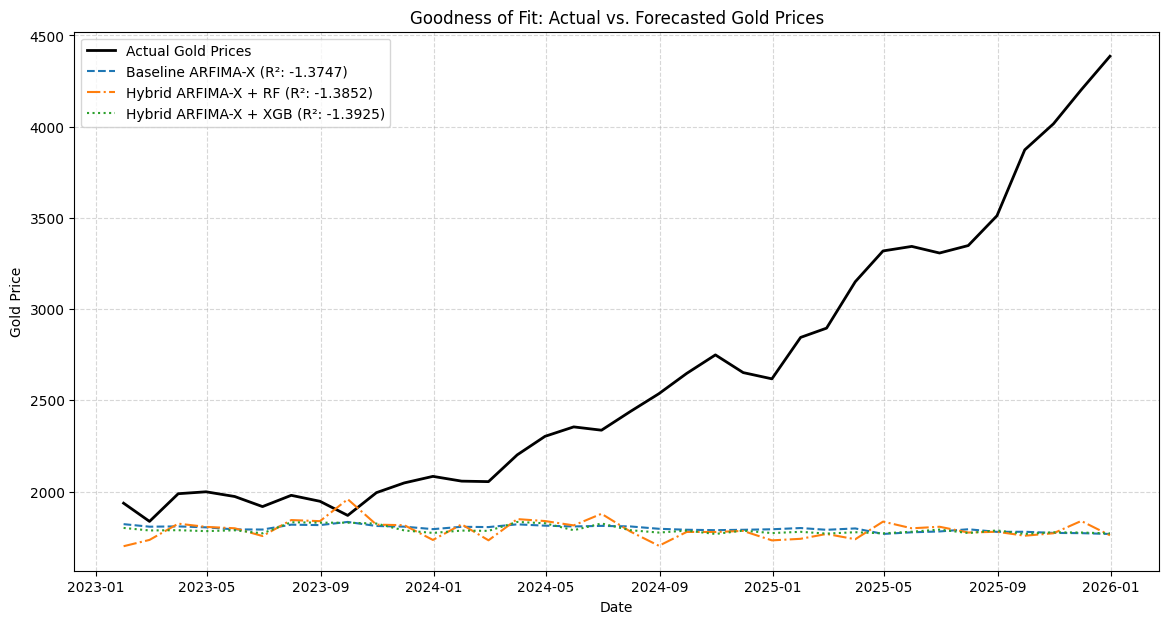

In [42]:
# Plot actual vs. predicted values for all specifications
try:
    import matplotlib.pyplot as plt

    plt.figure(figsize=(14, 7))
    plt.plot(y_test.index, y_test.values, label='Actual Gold Prices', color='black', linewidth=2)
    plt.plot(y_test.index, forecast_baseline, label=f'Baseline ARFIMA-X (R²: {r2_baseline:.4f})', linestyle='--')
    plt.plot(y_test.index, forecast_rf_hybrid, label=f'Hybrid ARFIMA-X + RF (R²: {r2_rf:.4f})', linestyle='-.')
    plt.plot(y_test.index, forecast_xgb_hybrid, label=f'Hybrid ARFIMA-X + XGB (R²: {r2_xgb:.4f})', linestyle=':')

    plt.title('Goodness of Fit: Actual vs. Forecasted Gold Prices')
    plt.xlabel('Date')
    plt.ylabel('Gold Price')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()
except NameError:
    print("Variables 'y_test' and model forecasts are not populated yet. Please upload the data file and run the cells above.")

### Neural Network Approach: LSTM (Long Short-Term Memory)

We will now build a Deep Learning benchmark using an LSTM network to capture sequential patterns. We'll use PyTorch to create a model that takes sequential windows of past gold prices along with the exogenous oil price to predict the next step's gold price.

In [43]:
import torch
import torch.nn as nn
from sklearn.preprocessing import MinMaxScaler

# 1. Prepare sequential data for LSTM
# Combine Gold (target) and Oil (exogenous) features
data_combined = np.column_stack((y.values, x.values))

# Scale the features to (0, 1) to aid neural network convergence
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(data_combined)

# Sequence window size
seq_length = 6

def create_sequences(data, seq_length):
    xs, ys = [], []
    for i in range(len(data) - seq_length):
        x_seq = data[i:(i + seq_length), :]  # Exogenous + target as inputs
        y_val = data[i + seq_length, 0]      # Target (Gold) as output
        xs.append(x_seq)
        ys.append(y_val)
    return np.array(xs), np.array(ys)

X_seq, y_seq = create_sequences(scaled_data, seq_length)

# Splitting sequence data matching our 80/20 temporal split
# The split point must align with the test set index of y_test (last 36 points of the original series)
# Since we lost 'seq_length' samples from the beginning, the test set size remains 36
train_size = len(X_seq) - 36
X_train_seq, X_test_seq = X_seq[:train_size], X_seq[train_size:]
y_train_seq, y_test_seq = y_seq[:train_size], y_seq[train_size:]

# Convert to PyTorch tensors
X_train_t = torch.tensor(X_train_seq, dtype=torch.float32)
y_train_t = torch.tensor(y_train_seq, dtype=torch.float32).unsqueeze(-1)
X_test_t = torch.tensor(X_test_seq, dtype=torch.float32)

# 2. Define LSTM Architecture
class LSTMForecaster(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_layers, output_dim):
        super(LSTMForecaster, self).__init__()
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers
        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim)
        out, _ = self.lstm(x, (h0, c0))
        out = self.fc(out[:, -1, :])
        return out

# Hyperparameters
input_dim = 2
hidden_dim = 32
num_layers = 1
output_dim = 1
num_epochs = 150
learning_rate = 0.01

model_lstm = LSTMForecaster(input_dim, hidden_dim, num_layers, output_dim)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model_lstm.parameters(), lr=learning_rate)

# 3. Model Training
model_lstm.train()
for epoch in range(num_epochs):
    outputs = model_lstm(X_train_t)
    optimizer.zero_grad()
    loss = criterion(outputs, y_train_t)
    loss.backward()
    optimizer.step()

# 4. Out-of-sample Forecast generation
model_lstm.eval()
with torch.no_grad():
    lstm_predictions_scaled = model_lstm(X_test_t).numpy()

# Rescale target prediction back to original scale
# To inverse scale only the target, we construct a dummy matrix
dummy = np.zeros((len(lstm_predictions_scaled), 2))
dummy[:, 0] = lstm_predictions_scaled.flatten()
forecast_lstm = scaler.inverse_transform(dummy)[:, 0]

# Evaluate LSTM performance
rmse_lstm = np.sqrt(mean_squared_error(y_test, forecast_lstm))
mae_lstm = mean_absolute_error(y_test, forecast_lstm)
mape_lstm = np.mean(np.abs((y_test.values - forecast_lstm) / y_test.values)) * 100
r2_lstm = r2_score(y_test, forecast_lstm)

# Display the metrics
print(f"LSTM Model - RMSE: {rmse_lstm:.4f}, MAE: {mae_lstm:.4f}, MAPE: {mape_lstm:.4f}%, R2: {r2_lstm:.4f}")

LSTM Model - RMSE: 167.4410, MAE: 130.0746, MAPE: 4.6220%, R2: 0.9460


In [44]:
# 5. Update complete Performance and Goodness of Fit table
new_row = {
    "Model": "LSTM Neural Network",
    "RMSE": rmse_lstm,
    "MAE": mae_lstm,
    "MAPE (%)": mape_lstm,
    "R-squared (R2)": r2_lstm
}

summary_df_updated = pd.concat([summary_df, pd.DataFrame([new_row])], ignore_index=True)
print("=== Updated Goodness of Fit & Performance Summary ===")
display(summary_df_updated.style.hide(axis='index'))

=== Updated Goodness of Fit & Performance Summary ===


Model,RMSE,MAE,MAPE (%),R-squared (R2)
Baseline ARFIMA-X,1110.315251,833.179510,26.914593,-1.374704
Hybrid ARFIMA-X + RF,1112.759126,844.432294,27.468000,-1.385169
Hybrid ARFIMA-X + XGB,1114.478673,841.223824,27.264900,-1.392547
LSTM Neural Network,167.440975,130.074598,4.622047,0.945994


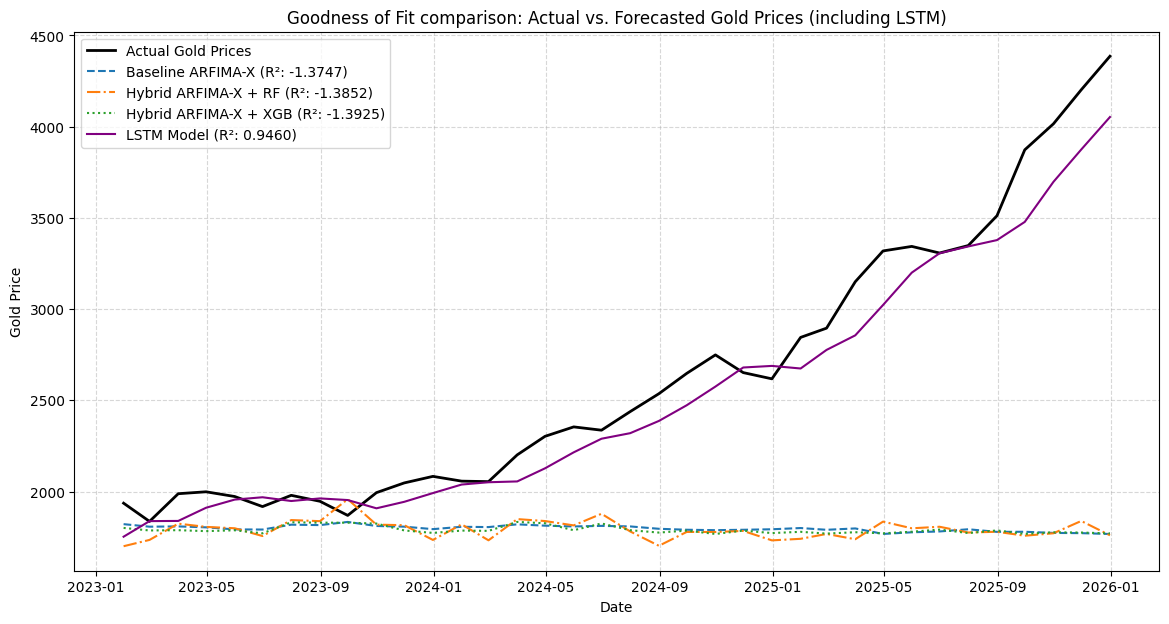

In [45]:
# 6. Plot performance comparisons including LSTM
plt.figure(figsize=(14, 7))
plt.plot(y_test.index, y_test.values, label='Actual Gold Prices', color='black', linewidth=2)
plt.plot(y_test.index, forecast_baseline, label=f'Baseline ARFIMA-X (R²: {r2_baseline:.4f})', linestyle='--')
plt.plot(y_test.index, forecast_rf_hybrid, label=f'Hybrid ARFIMA-X + RF (R²: {r2_rf:.4f})', linestyle='-.')
plt.plot(y_test.index, forecast_xgb_hybrid, label=f'Hybrid ARFIMA-X + XGB (R²: {r2_xgb:.4f})', linestyle=':')
plt.plot(y_test.index, forecast_lstm, label=f'LSTM Model (R²: {r2_lstm:.4f})', color='purple', linestyle='-')

plt.title('Goodness of Fit comparison: Actual vs. Forecasted Gold Prices (including LSTM)')
plt.xlabel('Date')
plt.ylabel('Gold Price')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()